# Quantum ML on Sensor Data: Fall Detection, Tested Honestly

> **Who is this for:** learners who have met quantum machine learning in [03_quantum_machine_learning.ipynb](03_quantum_machine_learning.ipynb) and want to see what happens when you apply it to a realistic task, instead of a toy dataset. Also useful if you work on wearables or health sensors and someone asks "should we use quantum AI for this?".
>
> **What you will learn:**
> - what **fall detection** from a wearable **accelerometer** looks like as a machine-learning problem (rare events, false alarms, missed falls)
> - how to **simulate** realistic accelerometer windows for daily activities and falls (free-fall dip, impact spike, stillness), for several people
> - how to turn a window into a few **features** (peak, minimum, post-impact variance, jerk) and then into **qubit angles**
> - how to evaluate fairly with **leave-one-subject-out** cross-validation and the right metrics: **sensitivity**, **specificity**, **false alarms** and **F1**, not just accuracy
> - an honest comparison of six models: a **threshold rule**, **logistic regression**, an **RBF SVM**, a small **MLP**, a **variational quantum classifier** (trained with the parameter-shift rule) and a **quantum-kernel SVM**
> - the effect of **shot noise** and simulated **hardware noise** on the quantum models
> - the practical trade-offs: **qubit count vs feature count**, **data encoding** choices, and **training cost**
> - a plain conclusion: which model wins, why classical is usually the right choice today, and when QML research might matter
>
> **Prerequisites:** [00 start here](00_start_here_quantum_computing_explained_simply.ipynb), [01 basics](01_quantum_computing_basics.ipynb) (the simulator), [03 quantum ML](03_quantum_machine_learning.ipynb) (encodings, variational circuits, parameter shift, quantum kernels). Classical side: [SVMs](../03_Machine_Learning/01_supervised/05_svm.ipynb), [neural network fundamentals](../05_Deep_Learning/01_neural_network_fundamentals.ipynb). For the full classical deep dive on this task (raw signals, more features, deep models), see [26_Sensor_AI/02_imu_activity_recognition_and_fall_detection.ipynb](../26_Sensor_AI/02_imu_activity_recognition_and_fall_detection.ipynb).
>
> **Time needed:** about 2 hours. The notebook runs in about 1.5-2 minutes on a laptop CPU (most of it is simulating the quantum circuits).
>
> **Runs on:** CPU, no API key, no internet. numpy, pandas, scikit-learn and matplotlib. An optional last cell checks the quantum circuit with PennyLane or Qiskit if one of them is installed, and prints "skipped" otherwise.

**Important:** all data here is **synthetic** (generated by code in this notebook). The numbers show how the methods compare on a plausible simulation; they are not clinical results.

## 0. Setup

Imports, a fixed random seed, and the small statevector simulator from notebook 01 (pasted in one cell so this notebook runs on its own). We use it to check the faster, batched simulator we write later.

In [1]:
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.model_selection import LeaveOneGroupOut, GroupKFold, GridSearchCV
from sklearn.metrics import f1_score
warnings.filterwarnings("ignore", category=UserWarning)

SEED = 42
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True)
pd.set_option("display.precision", 3)

In [2]:
# ---- The tiny statevector simulator from notebook 01 (same code, in one cell) ----
from collections import Counter

# Single-qubit gates (2x2 matrices)
I2 = np.eye(2, dtype=complex)
X = np.array([[0, 1], [1, 0]], dtype=complex)
Y = np.array([[0, -1j], [1j, 0]], dtype=complex)
Z = np.array([[1, 0], [0, -1]], dtype=complex)
H = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2)
S = np.array([[1, 0], [0, 1j]], dtype=complex)
T = np.array([[1, 0], [0, np.exp(1j * np.pi / 4)]], dtype=complex)

def RX(t): return np.array([[np.cos(t/2), -1j*np.sin(t/2)], [-1j*np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RY(t): return np.array([[np.cos(t/2), -np.sin(t/2)], [np.sin(t/2), np.cos(t/2)]], dtype=complex)
def RZ(t): return np.array([[np.exp(-1j*t/2), 0], [0, np.exp(1j*t/2)]], dtype=complex)

# Two-qubit gates (4x4). The first qubit listed is the control.
CNOT = np.array([[1,0,0,0],[0,1,0,0],[0,0,0,1],[0,0,1,0]], dtype=complex)
CZ = np.diag([1, 1, 1, -1]).astype(complex)

def apply_gate(psi, U, qubits, n):
    """Apply matrix U to the listed qubits of an n-qubit state psi.
    Qubit 0 is the LEFT-most bit of a bitstring like '011'."""
    k = len(qubits)
    psi = psi.reshape([2] * n)
    U = U.reshape([2] * (2 * k))
    psi = np.tensordot(U, psi, axes=(list(range(k, 2 * k)), list(qubits)))
    psi = np.moveaxis(psi, list(range(k)), list(qubits))
    return psi.reshape(-1)

class QSim:
    """A tiny statevector simulator. Methods return self, so calls can be chained."""
    def __init__(self, n):
        self.n = n
        self.psi = np.zeros(2 ** n, dtype=complex)
        self.psi[0] = 1.0                      # start in |00...0>
    def gate(self, U, *qubits):
        self.psi = apply_gate(self.psi, U, qubits, self.n); return self
    def x(self, q):  return self.gate(X, q)
    def y(self, q):  return self.gate(Y, q)
    def z(self, q):  return self.gate(Z, q)
    def h(self, q):  return self.gate(H, q)
    def s(self, q):  return self.gate(S, q)
    def t(self, q):  return self.gate(T, q)
    def rx(self, th, q): return self.gate(RX(th), q)
    def ry(self, th, q): return self.gate(RY(th), q)
    def rz(self, th, q): return self.gate(RZ(th), q)
    def cx(self, c, t): return self.gate(CNOT, c, t)
    def cz(self, a, b): return self.gate(CZ, a, b)
    def probs(self):
        return np.abs(self.psi) ** 2
    def measure(self, shots=1000, seed=0):
        """Sample bitstrings like a real device would. Returns a Counter."""
        rng = np.random.default_rng(seed)
        p = self.probs(); p = p / p.sum()
        idx = rng.choice(len(p), size=shots, p=p)
        return Counter(format(i, f"0{self.n}b") for i in idx)

def bitstrings(n):
    return [format(i, f"0{n}b") for i in range(2 ** n)]

def plot_counts(counts, title="", ax=None):
    """Bar chart of measurement counts, with every bitstring on the x-axis."""
    n = len(next(iter(counts)))
    labels = bitstrings(n)
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 2.6))
    ax.bar(labels, [counts.get(b, 0) for b in labels], color="tab:blue")
    ax.set_title(title); ax.set_ylabel("counts")
    ax.tick_params(axis="x", rotation=90 if n > 3 else 0)
    plt.tight_layout()
    return ax

def show_state(psi, tol=1e-9):
    """Print the non-zero amplitudes of a state in ket notation."""
    n = int(np.log2(len(psi)))
    for i, a in enumerate(psi):
        if abs(a) > tol:
            print(f"  |{format(i, f'0{n}b')}>  amplitude {a.real:+.3f}{a.imag:+.3f}j   probability {abs(a)**2:.3f}")

print("Simulator ready: QSim, apply_gate, gates X Y Z H S T RX RY RZ CNOT CZ, plot_counts, show_state")

Simulator ready: QSim, apply_gate, gates X Y Z H S T RX RY RZ CNOT CZ, plot_counts, show_state


## 1. The task: detect falls from a wearable accelerometer

**What it is.** **Fall detection** means automatically spotting that a person has fallen, so that help can be called. A common sensor is an **accelerometer**: a tiny chip (in a phone, watch or pendant) that measures acceleration along three axes (x, y, z). It is measured in **g**, where 1 g is the pull of gravity. Standing still, the sensor reads about 1 g in total.

**Simple analogy.** The accelerometer is like a cup of water carried by the person. Walking makes the water slosh gently. A fall makes it go weightless for a moment, then slam, then lie still.

**How a fall looks in the signal.** We look at the **magnitude** (total size) of the 3-axis signal, $\sqrt{a_x^2 + a_y^2 + a_z^2}$, which does not depend on how the device sits in a pocket.

```
magnitude (g)
  4 |                 *  <- impact spike (hitting the floor)
  3 |                 *
  2 |                **
  1 |~~~~~~~~~~~~    * *  ~~~~~~~~~~~~~~~~~~~~   <- stillness afterwards (lying)
  0 |            \__/       <- free-fall dip (nearly weightless)
     ------------------------------------------> time
        normal     fall   impact   lying still
```

**Why it is hard.**
- **Falls are rare.** Most windows are normal activity. A model that always says "no fall" gets high accuracy and is useless.
- **Some normal activities look like falls.** Jumping has a weightless phase and a landing spike. Dropping hard onto a sofa has a spike followed by stillness.
- **People differ.** Height, weight, walking style and how they fall all change the signal. A model must work on **new people** it has never seen.
- **Both kinds of errors matter.** A **missed fall** can be dangerous; a **false alarm** annoys the user and the carers, and users switch off devices that cry wolf.

This notebook keeps the classical side short (features plus standard models) and spends the time on the quantum side. The repo's sensor track goes much deeper on the classical side: [26_Sensor_AI/02_imu_activity_recognition_and_fall_detection.ipynb](../26_Sensor_AI/02_imu_activity_recognition_and_fall_detection.ipynb).

## 2. Simulate a realistic dataset

**What we generate.** 4-second windows sampled at 50 Hz (200 samples, 3 axes) for 8 simulated people ("subjects"). Each subject has their own body scale, walking speed, sensor noise and fall style, and wears the device at a random angle.

| Activity | What the signal does | Hard for a simple rule? |
|---|---|---|
| walk | gentle rhythm around 1 g | no |
| run | strong rhythm, high peaks and low dips | partly (high peaks) |
| still | flat at 1 g | no |
| sit (sit down normally) | small dip, small bump, then still, body tilted | no |
| lie (lie down on a bed) | slow tilt, small bumps, then still | partly (stillness) |
| jump | weightless phase, big landing spike, then moving again | **yes** |
| flop (drop hard onto a sofa) | dip, medium spike, then still | **yes** |
| **fall** | normal, free-fall dip, impact spike (soft or hard), then still lying (some people try to get up) | this is the target |

Each subject records 60 normal windows and 6 falls, so falls are about 9% of the data. The generator is simple physics plus randomness; real data is messier (see section 15).

In [3]:
FS, WIN = 50, 200                      # 50 samples per second, 4-second windows
t = np.arange(WIN) / FS                # time axis in seconds
UP = np.array([0.0, 0.0, 1.0])

def unit(v):
    return v / np.linalg.norm(v, axis=-1, keepdims=True)

def bump(center, width, height):
    """A smooth bump in time (Gaussian shape)."""
    return height * np.exp(-0.5 * ((t - center) / width) ** 2)

def tilt_gravity(start, rate, direction, amount=1.0):
    """Gravity direction that turns from upright toward `direction` around time `start`."""
    s = amount / (1 + np.exp(-(t - start) * rate))           # smooth 0 -> amount step
    return unit((1 - s)[:, None] * UP + s[:, None] * direction + 1e-6)

def random_rotation(rng):
    """A random 3-D rotation: the device sits at a different angle for each subject."""
    q, r = np.linalg.qr(rng.normal(size=(3, 3)))
    return q * np.sign(np.diag(r))

In [4]:
def make_window(kind, subj, rng):
    """One (200, 3) accelerometer window in g, in the device's own frame."""
    s, f = subj["scale"], subj["gait"] * rng.uniform(0.9, 1.1)
    grav = np.tile(UP, (WIN, 1))          # gravity direction over time (upright)
    dyn = np.zeros(WIN)                    # extra up/down acceleration from movement
    ev = rng.uniform(1.2, 2.0)             # when the event happens
    if kind == "walk":
        A = 0.3 * s * rng.uniform(0.8, 1.3)
        dyn = A * np.sin(2 * np.pi * f * t + rng.uniform(0, 6)) + 0.3 * A * np.sin(4 * np.pi * f * t)
    elif kind == "run":
        A = 0.85 * s * rng.uniform(0.8, 1.2); f = 1.45 * f
        dyn = A * np.sin(2 * np.pi * f * t + rng.uniform(0, 6)) + 0.35 * A * np.sin(4 * np.pi * f * t)
    elif kind == "still":
        dyn = 0.02 * np.sin(2 * np.pi * 0.3 * t)
    elif kind == "sit":
        dyn = -bump(ev, 0.15, 0.3 * s) + bump(ev + 0.3, 0.07, 0.5 * s * rng.uniform(0.7, 1.3))
        grav = tilt_gravity(ev, 8, np.array([1.0, 0, 0]), 0.3)
    elif kind == "lie":
        dyn = bump(ev, 0.2, 0.25 * s) + bump(ev + 0.6, 0.1, 0.25 * s)
        grav = tilt_gravity(ev, 3, unit(np.array([1.0, 0.2, 0])))
    elif kind == "jump":
        dyn = np.where(np.abs(t - ev) < 0.15, -0.8 * rng.uniform(0.7, 0.95), 0.0)      # in the air
        dyn = dyn + bump(ev + 0.2, 0.04, s * rng.uniform(1.4, 3.0))                   # landing
        dyn = dyn + (t > ev + 0.5) * 0.3 * s * np.sin(2 * np.pi * f * t)              # walks on
    elif kind == "flop":
        dyn = -bump(ev, 0.12, 0.45 * s) + bump(ev + 0.25, 0.04, s * rng.uniform(0.7, 1.9))
        grav = tilt_gravity(ev, 10, np.array([1.0, 0, 0]), 0.4)
    elif kind == "fall":
        dyn = (t < ev) * 0.25 * s * np.sin(2 * np.pi * f * t) * rng.integers(0, 2)  # walking or standing before
        dur = rng.uniform(0.15, 0.4) * subj["fallspeed"]                             # free-fall time
        dyn = dyn - rng.uniform(0.4, 0.9) * ((t >= ev) & (t < ev + dur))              # weightless dip
        imp = ev + dur
        dyn = dyn + bump(imp, 0.035, s * subj["impact"] * rng.uniform(1.0, 4.5))     # impact (soft or hard)
        dyn = dyn + bump(imp + 0.15, 0.05, 0.4 * rng.uniform(0, 1))                  # small rebound
        grav = tilt_gravity(imp, 15, unit(np.array([1.0, rng.uniform(-1, 1), 0])))   # ends up lying
        if rng.random() < 0.2:                                                        # tries to get up
            dyn = dyn + (t > imp + 1.2) * 0.25 * np.sin(2 * np.pi * 1.2 * t)
    acc = grav + dyn[:, None] * UP                                    # body frame, in g
    acc = acc @ subj["rotation"].T                                    # device worn at an angle
    return acc + rng.normal(0, subj["noise"], acc.shape)              # sensor noise

ADL = ["walk", "walk", "run", "still", "still", "sit", "sit", "lie", "jump", "flop"]   # ADL = activities of daily living

def make_dataset(n_subjects=8, n_adl=60, n_fall=6, rng=rng):
    windows, labels, subjects, kinds = [], [], [], []
    for sid in range(n_subjects):
        subj = dict(scale=rng.uniform(0.75, 1.25), gait=rng.uniform(1.6, 2.1), noise=rng.uniform(0.02, 0.05),
                    impact=rng.uniform(0.7, 1.2), fallspeed=rng.uniform(0.8, 1.2), rotation=random_rotation(rng))
        todo = [ADL[k] for k in rng.integers(len(ADL), size=n_adl)] + ["fall"] * n_fall
        for kind in todo:
            windows.append(make_window(kind, subj, rng)); labels.append(int(kind == "fall"))
            subjects.append(sid); kinds.append(kind)
    return np.stack(windows), np.array(labels), np.array(subjects), np.array(kinds)

windows, y, groups, kinds = make_dataset()
print("windows:", windows.shape, "(number, samples, axes)")
print(f"falls: {y.sum()} of {len(y)} windows ({100 * y.mean():.1f}%)")
print(pd.crosstab(kinds, groups, margins=True).rename_axis(index="activity", columns="subject"))

windows: (528, 200, 3) (number, samples, axes)
falls: 48 of 528 windows (9.1%)
subject    0   1   2   3   4   5   6   7  All
activity                                     
fall       6   6   6   6   6   6   6   6   48
flop       5   9   5   5   7   7   2   7   47
jump       5   9   6   6   3   6  10   6   51
lie        8   6   6  10   7  12   7   7   63
run        3   5   6   3   5   6   6   7   41
sit       10   6  15  11  13  10  11  11   87
still     17  12  11  18  11   8  11  12  100
walk      12  13  11   7  14  11  13  10   91
All       66  66  66  66  66  66  66  66  528


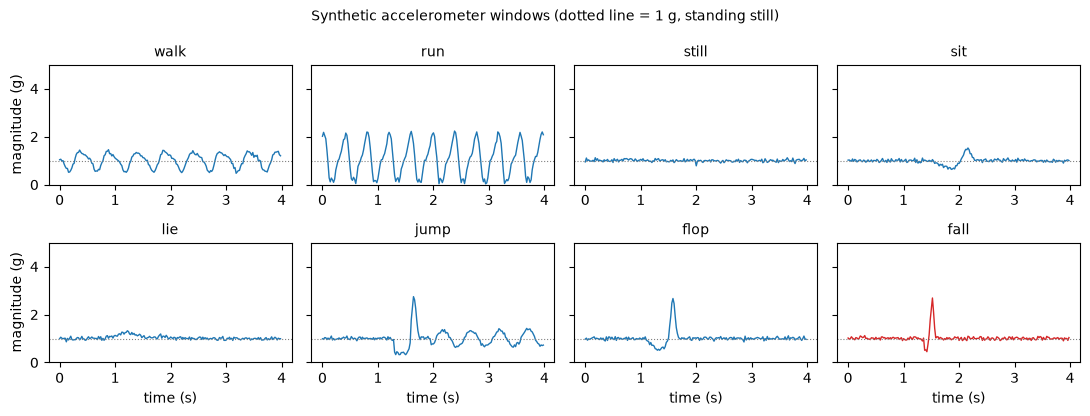

In [5]:
# One example window per activity: the magnitude of the 3-axis signal
mag = np.linalg.norm(windows, axis=2)
fig, axes = plt.subplots(2, 4, figsize=(11, 4.2), sharey=True)
for ax, kind in zip(axes.ravel(), ["walk", "run", "still", "sit", "lie", "jump", "flop", "fall"]):
    i = np.where(kinds == kind)[0][0]
    ax.plot(t, mag[i], color="tab:red" if kind == "fall" else "tab:blue", lw=1)
    ax.axhline(1, color="gray", ls=":", lw=0.8)
    ax.set_title(kind, fontsize=10); ax.set_ylim(0, 5)
for ax in axes[:, 0]: ax.set_ylabel("magnitude (g)")
for ax in axes[1]: ax.set_xlabel("time (s)")
plt.suptitle("Synthetic accelerometer windows (dotted line = 1 g, standing still)", fontsize=10)
plt.tight_layout(); plt.show()

**What just happened?** We made 528 windows from 8 people; 48 are falls. In the plots, the fall shows the classic pattern: a dip below 1 g (free fall), a sharp spike (impact), then a flat line (lying still). Jump and flop share parts of that pattern, which is what makes the task interesting.

## 3. From windows to a few features

**What it is.** A **feature** is one number that summarises a window. Quantum models today can only take a handful of numbers (each one usually needs its own qubit), so we pick a few strong, physically meaningful features.

| Feature | Plain meaning | Fall pattern |
|---|---|---|
| **peak** | largest magnitude in the window (g) | high (impact) |
| **min** | smallest magnitude (g) | low (free fall) |
| **post_var** | variance of the magnitude from 0.5 s to 1.5 s after the peak | very low (lying still) |
| **jerk** | largest change of magnitude between two samples, per second (g/s) | high (sudden impact) |

**Variance** measures how much a signal wiggles around its average; **jerk** is how fast acceleration changes.

In [6]:
def extract_features(windows):
    mag = np.linalg.norm(windows, axis=2)
    peak_idx = mag.argmax(axis=1)
    peak = mag.max(axis=1)
    mn = mag.min(axis=1)
    post_var = np.array([m[min(i + 25, WIN - 20): min(i + 75, WIN)].var() for m, i in zip(mag, peak_idx)])
    jerk = np.abs(np.diff(mag, axis=1)).max(axis=1) * FS
    return pd.DataFrame({"peak": peak, "min": mn, "post_var": post_var, "jerk": jerk})

feats = extract_features(windows)
feats["activity"] = kinds
print("Median feature value per activity:")
print(feats.groupby("activity")[["peak", "min", "post_var", "jerk"]].median().round(3))

Median feature value per activity:
           peak    min  post_var    jerk
activity                                
fall      2.667  0.295     0.002  42.321
flop      1.933  0.593     0.002  18.096
jump      2.997  0.296     0.032  61.463
lie       1.237  0.891     0.002   8.876
run       1.919  0.094     0.302  25.124
sit       1.437  0.685     0.002   9.311
still     1.125  0.886     0.002   8.704
walk      1.377  0.616     0.045  10.871


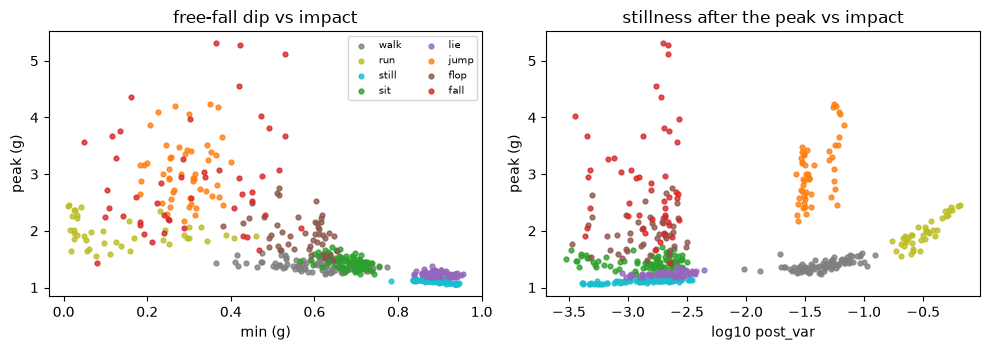

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
for kind, col in [("walk", "tab:gray"), ("run", "tab:olive"), ("still", "tab:cyan"), ("sit", "tab:green"),
                  ("lie", "tab:purple"), ("jump", "tab:orange"), ("flop", "tab:brown"), ("fall", "tab:red")]:
    m = kinds == kind
    axes[0].scatter(feats["min"][m], feats["peak"][m], s=12, c=col, label=kind, alpha=0.8)
    axes[1].scatter(np.log10(feats["post_var"][m]), feats["peak"][m], s=12, c=col, alpha=0.8)
axes[0].set_xlabel("min (g)"); axes[0].set_ylabel("peak (g)"); axes[0].legend(fontsize=7, ncol=2)
axes[1].set_xlabel("log10 post_var"); axes[1].set_ylabel("peak (g)")
axes[0].set_title("free-fall dip vs impact"); axes[1].set_title("stillness after the peak vs impact")
plt.tight_layout(); plt.show()

**What just happened?** Falls (red) sit at low **min** and high **peak**, but jumps and flops overlap them in the left plot. The right plot separates jumps (they keep moving, so post_var is high) but flops still overlap, because a hard sofa drop also ends in stillness. Soft falls (small impact) overlap with normal activities too. No single feature solves the problem; this is a realistic, imperfect task.

## 4. From features to qubit angles

**What it is.** Most quantum classifiers read data through **angle encoding**: each feature becomes the rotation angle of one qubit (notebook 03, section 2). So the pipeline is:

```mermaid
flowchart LR
    W[raw window<br/>200 x 3 numbers] --> F[4 features<br/>peak, min, post_var, jerk]
    F --> L[log of post_var and jerk<br/>they span many orders of magnitude]
    L --> S[standardise<br/>mean 0, spread 1]
    S --> P[optional PCA<br/>4 -> 2 numbers]
    P --> A[min-max scale<br/>to angles 0 ... pi]
    A --> Q[one qubit per number<br/>RY angle]
```

**Rule against leakage.** Every scaler and the PCA are **fitted on the training people only**, inside each cross-validation fold, then applied to the test person. Fitting them on all data would let the test person's statistics leak into training.

**PCA** (principal component analysis) finds the directions in which the data varies most, so 4 numbers can be squeezed into 2 with little loss. Fewer numbers means fewer qubits.

In [8]:
def base_features(F):
    """4 features with log transforms on the long-tailed ones."""
    return np.c_[F["peak"], F["min"], np.log10(F["post_var"] + 1e-4), np.log10(F["jerk"])]

X = base_features(feats)
pca_all = PCA().fit(StandardScaler().fit_transform(X))      # only for this printout; the folds refit PCA
print("share of variance kept by 1, 2, 3, 4 PCA components:", np.cumsum(pca_all.explained_variance_ratio_).round(3))

def to_angles(X_tr, X_te, n_components=None):
    """Fit on the training rows only, then map both sets to angles in [0, pi]."""
    sc = StandardScaler().fit(X_tr)
    A_tr, A_te = sc.transform(X_tr), sc.transform(X_te)
    if n_components is not None:
        pca = PCA(n_components).fit(A_tr)
        A_tr, A_te = pca.transform(A_tr), pca.transform(A_te)
    mm = MinMaxScaler((0, np.pi)).fit(A_tr)
    return np.clip(mm.transform(A_tr), 0, np.pi), np.clip(mm.transform(A_te), 0, np.pi)

A_tr_demo, _ = to_angles(X, X)
print("angles for the first 3 windows (radians):\n", A_tr_demo[:3])

share of variance kept by 1, 2, 3, 4 PCA components: [0.719 0.933 0.98  1.   ]
angles for the first 3 windows (radians):
 [[0.349 2.078 0.657 0.918]
 [0.05  2.57  0.705 1.141]
 [0.063 2.747 0.902 0.789]]


**Qubit count vs feature count.** With angle encoding, **one qubit per number**. That is why we reduce to 2-4 numbers:

| Input to the quantum model | Angle encoding | Amplitude encoding (numbers stored as amplitudes) | Comment |
|---|---|---|---|
| 2 PCA components | 2 qubits | 1 qubit | tiny; easy to simulate |
| 4 features | 4 qubits | 2 qubits | what we use below |
| raw window, 200 x 3 = 600 numbers | 600 qubits | 10 qubits ($2^{10} = 1024 \geq 600$) | angle: impossible to simulate and far beyond clean hardware; amplitude: needs a deep loading circuit with roughly as many gates as numbers, for **every** window |

So on today's devices, quantum models see a few hand-made features, not the raw signal. A classical model can use all 600 numbers (and the sensor track does).

## 5. How we evaluate: leave-one-subject-out and the right metrics

**Leave-one-subject-out (LOSO) cross-validation.** Train on 7 people, test on the 8th; repeat for every person; pool the 8 test results. This answers the real question: "does it work on someone new?". Splitting windows at random would put the same person in training and test, and give over-optimistic numbers.

```mermaid
flowchart LR
    D[8 subjects] --> F1[fold 1: train on 2-8<br/>test on 1]
    D --> F2[fold 2: train on 1, 3-8<br/>test on 2]
    D --> F8[... fold 8: train on 1-7<br/>test on 8]
    F1 --> P[pool all test predictions<br/>-> one confusion matrix]
    F2 --> P
    F8 --> P
```

**Metrics.** A **confusion matrix** counts the four outcomes: TP (fall, detected), FN (fall, missed), FP (no fall, alarm: a **false alarm**), TN (no fall, no alarm).

| Metric | Formula | Plain question |
|---|---|---|
| **Sensitivity** (recall) | TP / (TP + FN) | of the real falls, how many did we catch? |
| **Specificity** | TN / (TN + FP) | of the normal windows, how many did we correctly leave alone? |
| **False alarms** | FP (and FP per 1,000 normal windows) | how often do we cry wolf? |
| **Precision** | TP / (TP + FP) | when we raise an alarm, how often is it a real fall? |
| **F1** | 2 · precision · sensitivity / (precision + sensitivity) | one number balancing catching falls and avoiding false alarms |
| Accuracy | (TP + TN) / all | **misleading** when falls are rare (see below) |

In [9]:
def evaluate(y_true, y_pred):
    """Fall-detection metrics from pooled predictions."""
    tp = int(((y_true == 1) & (y_pred == 1)).sum()); fn = int(((y_true == 1) & (y_pred == 0)).sum())
    fp = int(((y_true == 0) & (y_pred == 1)).sum()); tn = int(((y_true == 0) & (y_pred == 0)).sum())
    sens = tp / max(tp + fn, 1); spec = tn / max(tn + fp, 1); prec = tp / max(tp + fp, 1)
    f1 = 2 * prec * sens / max(prec + sens, 1e-12)
    return {"sensitivity": sens, "specificity": spec, "false_alarms": fp, "FA_per_1000": 1000 * fp / max(tn + fp, 1),
            "missed_falls": fn, "precision": prec, "F1": f1, "accuracy": (tp + tn) / len(y_true)}

logo = LeaveOneGroupOut()
results = {}                                            # model name -> metrics
oof = {}                                                # model name -> pooled out-of-fold predictions
times = {}                                              # model name -> total training time (s)

# The "never alarm" model: high accuracy, zero use
results["always 'no fall'"] = evaluate(y, np.zeros_like(y))
print(pd.Series(results["always 'no fall'"]).round(3).to_string())

sensitivity      0.000
specificity      1.000
false_alarms     0.000
FA_per_1000      0.000
missed_falls    48.000
precision        0.000
F1               0.000
accuracy         0.909


**What just happened?** A model that never raises an alarm gets about **91% accuracy** because falls are rare, yet it misses every fall (sensitivity 0, F1 0). That is why we report sensitivity, specificity, false alarms and F1. In a real product you would also fix a target (for example "catch at least 95% of falls") and then minimise false alarms.

## 6. Classical baselines

Four classical models, all trained and tested with the same LOSO folds:

1. **Threshold rule.** "Alarm if peak > a AND min < b AND post_var < c." This is what many simple devices do. We choose a, b, c from a small grid by the best F1 **on the training people** of each fold.
2. **Logistic regression** (a straight-line boundary) with class weights, so rare falls count as much as common normal windows.
3. **RBF SVM** (a curved boundary from a kernel; see [05_svm](../03_Machine_Learning/01_supervised/05_svm.ipynb)), class-weighted; its width parameter `gamma` is tuned by an inner cross-validation over the training people.
4. **Small MLP** (a neural network with 16 hidden units). scikit-learn's MLP has no class weights, so we **oversample** falls (repeat them) in training.

The four features (with log transforms) are standardised inside each fold.

In [10]:
def threshold_rule_fit(F_tr, y_tr):
    best, best_f1 = None, -1
    for a in [1.8, 2.0, 2.2, 2.5, 3.0]:
        for b in [0.4, 0.5, 0.6, 0.7]:
            for c_ in [0.005, 0.01, 0.03, 0.1]:
                pred = ((F_tr[:, 0] > a) & (F_tr[:, 1] < b) & (F_tr[:, 2] < c_)).astype(int)
                f = f1_score(y_tr, pred, zero_division=0)
                if f > best_f1: best, best_f1 = (a, b, c_), f
    return best

def threshold_rule_predict(F_te, abc):
    a, b, c_ = abc
    return ((F_te[:, 0] > a) & (F_te[:, 1] < b) & (F_te[:, 2] < c_)).astype(int)

F_raw = feats[["peak", "min", "post_var"]].to_numpy()

def run_classical(name, fit_predict):
    pred = np.zeros_like(y); t0 = time.perf_counter()
    for tr, te in logo.split(X, y, groups):
        pred[te] = fit_predict(tr, te)
    times[name] = time.perf_counter() - t0
    oof[name] = pred; results[name] = evaluate(y, pred)

chosen = []
def rule_fp(tr, te):
    abc = threshold_rule_fit(F_raw[tr], y[tr]); chosen.append(abc)
    return threshold_rule_predict(F_raw[te], abc)

def logreg_fp(tr, te):
    sc = StandardScaler().fit(X[tr])
    return LogisticRegression(class_weight="balanced").fit(sc.transform(X[tr]), y[tr]).predict(sc.transform(X[te]))

def rbf_fp(tr, te):
    sc = StandardScaler().fit(X[tr])
    grid = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"), {"gamma": [0.05, 0.1, 0.25, 0.5, 1.0]},
                        cv=GroupKFold(n_splits=7), scoring="f1")
    grid.fit(sc.transform(X[tr]), y[tr], groups=groups[tr])
    return grid.predict(sc.transform(X[te]))

def mlp_fp(tr, te):
    sc = StandardScaler().fit(X[tr]); Xtr, ytr = sc.transform(X[tr]), y[tr]
    reps = int(round((ytr == 0).sum() / (ytr == 1).sum())) - 1          # repeat falls to balance the classes
    idx = np.r_[np.arange(len(ytr)), np.repeat(np.where(ytr == 1)[0], reps)]
    mlp = MLPClassifier(hidden_layer_sizes=(16,), max_iter=2000, random_state=SEED).fit(Xtr[idx], ytr[idx])
    return mlp.predict(sc.transform(X[te]))

run_classical("threshold rule", rule_fp)
run_classical("logistic regression", logreg_fp)
run_classical("RBF SVM", rbf_fp)
run_classical("MLP (16 hidden)", mlp_fp)
print("thresholds chosen in the 8 folds (peak >, min <, post_var <):", sorted(set(chosen)))

def show(names):
    df = pd.DataFrame({n: results[n] for n in names}).T
    df["false_alarms"] = df["false_alarms"].astype(int); df["missed_falls"] = df["missed_falls"].astype(int)
    return df[["sensitivity", "specificity", "false_alarms", "FA_per_1000", "missed_falls", "precision", "F1", "accuracy"]].round(3)

show(["always 'no fall'", "threshold rule", "logistic regression", "RBF SVM", "MLP (16 hidden)"])

thresholds chosen in the 8 folds (peak >, min <, post_var <): [(1.8, 0.5, 0.005)]


,sensitivity,specificity,false_alarms,FA_per_1000,missed_falls,precision,F1,accuracy
always 'no fall',0.000,1.000,0,0.000,48,0.000,0.000,0.909
threshold rule,0.875,0.985,7,14.583,6,0.857,0.866,0.975
logistic regression,0.958,0.971,14,29.167,2,0.767,0.852,0.970
RBF SVM,0.938,0.971,14,29.167,3,0.763,0.841,0.968
MLP (16 hidden),0.979,0.973,13,27.083,1,0.783,0.870,0.973


**What just happened?**
- The tuned **threshold rule** is a surprisingly strong baseline here, because the features were designed with fall physics in mind. But it **misses more falls** (soft falls with a small impact slip under its fixed peak threshold), while raising few false alarms.
- The three learned classical models catch almost every fall (46-47 of 48). They pay with more false alarms, because the class weighting tells them that missing a fall is expensive. For a fall detector that is usually the right trade-off, and you could move it with the decision threshold.
- These are the numbers the quantum models must beat.

## 7. A variational quantum classifier (VQC)

**What it is.** A **variational quantum classifier** is a small quantum circuit with adjustable rotation angles (the "weights"), trained like a neural network (notebook 03, sections 3-6).

**Simple analogy.** A combination lock with 16 dials. Data sets some dials (the features), training turns the others until "fall" windows make the needle point one way and normal windows the other.

**How it works here.**
1. **Encode**: each of the 4 angles goes into one qubit as RY(angle).
2. **Trainable layer**: on every qubit RY(w) then RZ(w'), then a ring of CNOTs (0→1→2→3→0) to entangle the qubits.
3. Repeat steps 1-2 twice (**data re-uploading**: encoding the data more than once makes the model more flexible).
4. **Read out** $\langle Z_0\rangle$, the average of +1/−1 measurements of qubit 0, a number in [−1, 1].
5. A tiny classical step turns it into a fall probability: $p = \text{sigmoid}(a \langle Z_0\rangle + b)$, with two trainable numbers a and b. This handles the class imbalance (b shifts the decision threshold).

```
q0: -RY(x0)-RY(w)-RZ(w)-o-------X-   (x2 layers)   measure <Z> on q0
q1: -RY(x1)-RY(w)-RZ(w)-X-o-----|-
q2: -RY(x2)-RY(w)-RZ(w)---X-o---|-
q3: -RY(x3)-RY(w)-RZ(w)-----X---o-
```

That is 2 layers x 4 qubits x 2 = 16 circuit angles plus a and b. **Training**: weighted cross-entropy loss (falls weighted up), the **Adam** optimiser, and **parameter-shift** gradients: for each circuit angle, run the circuit at angle + π/2 and angle − π/2; half the difference is the exact derivative. On a simulator we could use cheaper backpropagation, but parameter shift is what real hardware needs, so we use it here.

**A faster simulator.** The `QSim` class handles one state at a time. Training needs about 33 circuits (1 + 2 × 16 shifts) for each of about 460 windows at every step, so we write a **batched** simulator: one row per (parameter setting, window). We use 32-bit complex numbers (`complex64`) to halve memory and time; this is plenty accurate for a classifier.

In [11]:
# ---- Batched statevector simulator: psi has shape (B, 2, 2, ..., 2), one state per row ----
CDT = np.complex64

def zero_states(B, n):
    psi = np.zeros((B,) + (2,) * n, dtype=CDT); psi[(slice(None),) + (0,) * n] = 1
    return psi

def _ix(q, bit):                       # index that picks qubit q = bit in every row
    return (slice(None),) * (q + 1) + (bit,)

def _col(v, n):                        # reshape a per-row number so it broadcasts over the other qubits
    return np.asarray(v).reshape((-1,) + (1,) * (n - 1))

def ry(psi, theta, q):
    n = psi.ndim - 1; th = np.asarray(theta, dtype=np.float64)
    c_, s_ = _col(np.cos(th / 2).astype(np.float32), n), _col(np.sin(th / 2).astype(np.float32), n)
    a0, a1 = psi[_ix(q, 0)], psi[_ix(q, 1)]; out = np.empty_like(psi)
    out[_ix(q, 0)] = c_ * a0 - s_ * a1; out[_ix(q, 1)] = s_ * a0 + c_ * a1
    return out

def rz(psi, theta, q):
    n = psi.ndim - 1; ph = _col(np.exp(0.5j * np.asarray(theta, dtype=np.float64)).astype(CDT), n)
    out = psi.copy(); out[_ix(q, 0)] *= ph.conj(); out[_ix(q, 1)] *= ph
    return out

def hadamard(psi, q):
    a0, a1 = psi[_ix(q, 0)], psi[_ix(q, 1)]; out = np.empty_like(psi)
    out[_ix(q, 0)] = (a0 + a1) / np.sqrt(2); out[_ix(q, 1)] = (a0 - a1) / np.sqrt(2)
    return out

def cnot(psi, ctrl, targ):
    """Flip qubit `targ` in the half of the state where qubit `ctrl` is 1."""
    out = psi.copy(); sl = [slice(None)] * psi.ndim; sl[ctrl + 1] = 1
    axis = targ + 1 - (1 if targ > ctrl else 0)          # target axis inside the selected half
    out[tuple(sl)] = np.flip(psi[tuple(sl)], axis=axis)
    return out

def expect_z0(psi):
    """<Z> on qubit 0 for every row: P(qubit 0 = 0) - P(qubit 0 = 1)."""
    p = np.abs(psi) ** 2; B = p.shape[0]
    return p[:, 0].reshape(B, -1).sum(1) - p[:, 1].reshape(B, -1).sum(1)

In [12]:
N_LAYERS = 2                           # default number of re-uploading layers

def layers_of(params, n):
    """How many layers a parameter vector holds (each layer: 2 angles per qubit; plus the 2 numbers a, b)."""
    return (len(params) - 2) // (2 * n)

def ring(n):
    """CNOT pairs of the entangling ring: (0,1), (1,2), ..., (n-1,0). For 2 qubits: (0,1) then (1,0),
    so that qubit 1's data can reach the measured qubit 0."""
    return [(0, 1), (1, 0)] if n == 2 else [(q, (q + 1) % n) for q in range(n)]

def vqc_circuit(A, W):
    """A: (B, n) angles; W: (K, layers, n, 2) circuit weights for K parameter settings.
    Returns the final states for all K x B combinations."""
    K = W.shape[0]; B, n = A.shape
    psi = zero_states(K * B, n); A_rep = np.tile(A, (K, 1))
    for l in range(W.shape[1]):
        for q in range(n):
            psi = ry(psi, A_rep[:, q], q)                          # encode (re-upload) the data
            psi = ry(psi, np.repeat(W[:, l, q, 0], B), q)          # trainable rotations
            psi = rz(psi, np.repeat(W[:, l, q, 1], B), q)
        for a, b in ring(n):
            psi = cnot(psi, a, b)                                  # entangle
    return psi

def vqc_expval(A, W):
    return expect_z0(vqc_circuit(A, W)).reshape(W.shape[0], A.shape[0])

# Check the batched simulator against the step-by-step QSim from notebook 01 on one random input
x_chk = rng.uniform(0, np.pi, 4); w_chk = rng.normal(0, 1, (N_LAYERS, 4, 2))
sim = QSim(4)
for l in range(N_LAYERS):
    for q in range(4):
        sim.ry(x_chk[q], q).ry(w_chk[l, q, 0], q).rz(w_chk[l, q, 1], q)
    for a, b in ring(4):
        sim.cx(a, b)
z0_qsim = sim.probs() @ np.array([1 - 2 * int(s[0]) for s in bitstrings(4)])
z0_fast = vqc_expval(x_chk[None, :], w_chk[None])[0, 0]
print(f"<Z0> from QSim: {z0_qsim:+.5f}   from the batched simulator: {z0_fast:+.5f}")

<Z0> from QSim: +0.20855   from the batched simulator: +0.20855


In [13]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def vqc_gradients(A, y, params, n, class_w):
    """Loss and exact gradients. Circuit angles: parameter-shift rule. a and b: ordinary calculus."""
    L = layers_of(params, n); P = L * n * 2
    w, a, b = params[:P], params[P], params[P + 1]
    shifts = np.r_[np.zeros((1, P)), np.eye(P) * np.pi / 2, -np.eye(P) * np.pi / 2]   # 1 + 2P settings
    E = vqc_expval(A, (w[None, :] + shifts).reshape(-1, L, n, 2))
    f = E[0]                                         # <Z0> at the current weights, one per window
    df_dw = (E[1:P + 1] - E[P + 1:]) / 2             # parameter-shift rule, shape (P, B)
    p = np.clip(sigmoid(a * f + b), 1e-7, 1 - 1e-7)
    loss = -np.mean(class_w * (y * np.log(p) + (1 - y) * np.log(1 - p)))
    dz = class_w * (p - y) / len(y)                  # d loss / d (a f + b)
    grad = np.r_[df_dw @ (dz * a), dz @ f, dz.sum()]
    return loss, grad

def train_vqc(A, y, steps=40, lr=0.2, seed=0, record=False, layers=N_LAYERS):
    n = A.shape[1]; r = np.random.default_rng(seed)
    params = np.r_[r.normal(0, 0.3, layers * n * 2), 2.0, 0.0]
    class_w = np.where(y == 1, 0.5 / y.mean(), 0.5 / (1 - y.mean()))   # falls count as much as normal windows
    m, v, hist = np.zeros_like(params), np.zeros_like(params), []
    for step in range(1, steps + 1):
        loss, g = vqc_gradients(A, y, params, n, class_w); hist.append(loss)
        m = 0.9 * m + 0.1 * g; v = 0.999 * v + 0.001 * g ** 2               # Adam
        params = params - lr * (m / (1 - 0.9 ** step)) / (np.sqrt(v / (1 - 0.999 ** step)) + 1e-8)
    return (params, hist) if record else params

def vqc_proba(A, params):
    n = A.shape[1]; L = layers_of(params, n); P = L * n * 2
    f = vqc_expval(A, params[:P].reshape(1, L, n, 2))[0]
    return sigmoid(params[P] * f + params[P + 1])

# Check the parameter-shift gradient against a finite-difference estimate on 30 windows
A_small = A_tr_demo[:30]; y_small = y[:30].astype(float); y_small[:3] = 1
cw = np.where(y_small == 1, 0.5 / y_small.mean(), 0.5 / (1 - y_small.mean()))
p0 = np.r_[rng.normal(0, 0.5, 16), 2.0, 0.0]
_, g_ps = vqc_gradients(A_small, y_small, p0, 4, cw)
eps, g_fd = 1e-3, []
for k in range(3):
    d = np.zeros_like(p0); d[k] = eps
    g_fd.append((vqc_gradients(A_small, y_small, p0 + d, 4, cw)[0] - vqc_gradients(A_small, y_small, p0 - d, 4, cw)[0]) / (2 * eps))
print("first 3 gradients, parameter shift :", g_ps[:3])
print("first 3 gradients, finite difference:", np.array(g_fd))

first 3 gradients, parameter shift : [-0.134  0.008 -0.001]
first 3 gradients, finite difference: [-0.134  0.008 -0.001]


VQC trained 8 times in 20.4 s


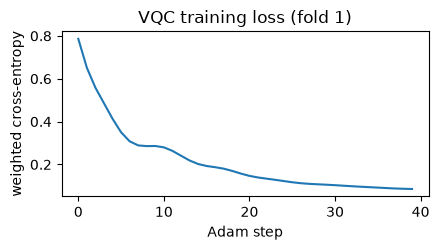

,sensitivity,specificity,false_alarms,FA_per_1000,missed_falls,precision,F1,accuracy
RBF SVM,0.938,0.971,14,29.167,3,0.763,0.841,0.968
MLP (16 hidden),0.979,0.973,13,27.083,1,0.783,0.870,0.973
VQC (4 qubits),0.979,0.971,14,29.167,1,0.770,0.862,0.972


In [14]:
# Train and test the VQC with leave-one-subject-out (4 features -> 4 qubits)
fold_store = []                                       # keep each fold's weights and test angles for sections 10-11
pred = np.zeros_like(y); proba = np.zeros(len(y)); t0 = time.perf_counter()
for k, (tr, te) in enumerate(logo.split(X, y, groups)):
    A_tr, A_te = to_angles(X[tr], X[te])
    if k == 0:
        params, hist = train_vqc(A_tr, y[tr], record=True)
    else:
        params = train_vqc(A_tr, y[tr])
    proba[te] = vqc_proba(A_te, params); pred[te] = proba[te] > 0.5
    fold_store.append((te, A_te, params))
times["VQC (4 qubits)"] = time.perf_counter() - t0
oof["VQC (4 qubits)"] = pred; results["VQC (4 qubits)"] = evaluate(y, pred)
print(f"VQC trained 8 times in {times['VQC (4 qubits)']:.1f} s")

plt.figure(figsize=(4.5, 2.6)); plt.plot(hist)
plt.xlabel("Adam step"); plt.ylabel("weighted cross-entropy"); plt.title("VQC training loss (fold 1)")
plt.tight_layout(); plt.show()
show(["RBF SVM", "MLP (16 hidden)", "VQC (4 qubits)"])

**What just happened?**
- The batched simulator agrees with `QSim`, and the parameter-shift gradients agree with finite differences (small differences come from 32-bit numbers and the finite step), so the training is doing what the theory says.
- The loss falls steadily, and the trained VQC is a reasonable fall detector: it catches most falls with a false-alarm level in the same range as the classical learned models. It does **not** clearly beat them, and it took far longer to train (compare the times in section 12).

## 8. A quantum-kernel SVM

**What it is.** A **quantum kernel** measures how similar two windows are by encoding each one into a quantum state and computing the overlap of the two states: $k(x, x') = |\langle\phi(x)|\phi(x')\rangle|^2$ (notebook 03, section 7). The SVM itself is classical; only the similarity numbers come from the quantum circuit.

**Simple analogy.** Two songs played through the same strange echo chamber; if the recordings overlap a lot, the songs are "similar".

**How it works here.**
1. Feature map: the ZZ feature map (Havlicek et al., 2019) on 4 qubits: H on every qubit, RZ(2x) on every qubit, then for each neighbouring pair a CNOT-RZ-CNOT block with angle $2(\pi - x_i)(\pi - x_j)$; repeated twice.
2. Kernel matrices for train-train and test-train pairs.
3. `SVC(kernel="precomputed", class_weight="balanced")`.
4. The input **scale** (multiply the angles by s before encoding) works like the width of an RBF kernel. We tune s by an inner cross-validation over the training people, exactly as we tuned `gamma` for the RBF SVM.

On hardware each kernel entry is the probability of measuring all zeros after running $U(x)$ then $U(x')^\dagger$, estimated from shots.

In [15]:
def zz_feature_map(A, reps=2):
    B, n = A.shape; psi = zero_states(B, n)
    for _ in range(reps):
        for q in range(n):
            psi = rz(hadamard(psi, q), 2 * A[:, q], q)
        for q in range(n - 1):
            psi = cnot(psi, q, q + 1)
            psi = rz(psi, 2 * (np.pi - A[:, q]) * (np.pi - A[:, q + 1]), q + 1)
            psi = cnot(psi, q, q + 1)
    return psi.reshape(B, -1)

def zz_kernel(A1, A2):
    return np.abs(zz_feature_map(A1).conj() @ zz_feature_map(A2).T) ** 2

def kernel_svm_loso(kernel_fn, scales, n_components=None, name=None):
    """LOSO for an SVM with a precomputed kernel; the scale is picked by inner CV on the training people."""
    pred = np.zeros_like(y); picked = []; t0 = time.perf_counter()
    for tr, te in logo.split(X, y, groups):
        A_tr, A_te = to_angles(X[tr], X[te], n_components)
        best_s, best_f1 = scales[0], -1
        for s in scales:                                   # inner CV: hold out one training person at a time
            K = kernel_fn(s * A_tr, s * A_tr); f1s = []
            for itr, ite in GroupKFold(n_splits=7).split(A_tr, y[tr], groups[tr]):
                m = SVC(kernel="precomputed", class_weight="balanced").fit(K[np.ix_(itr, itr)], y[tr][itr])
                f1s.append(f1_score(y[tr][ite], m.predict(K[np.ix_(ite, itr)]), zero_division=0))
            if np.mean(f1s) > best_f1: best_s, best_f1 = s, np.mean(f1s)
        picked.append(best_s)
        m = SVC(kernel="precomputed", class_weight="balanced").fit(kernel_fn(best_s * A_tr, best_s * A_tr), y[tr])
        pred[te] = m.predict(kernel_fn(best_s * A_te, best_s * A_tr))
    if name:
        times[name] = time.perf_counter() - t0; oof[name] = pred; results[name] = evaluate(y, pred)
    return pred, picked

SCALES = [0.1, 0.2, 0.35, 0.5, 1.0]
_, picked = kernel_svm_loso(zz_kernel, SCALES, name="quantum-kernel SVM (4 qubits)")
print("scale picked in each fold:", picked)
show(["RBF SVM", "MLP (16 hidden)", "VQC (4 qubits)", "quantum-kernel SVM (4 qubits)"])

scale picked in each fold: [0.2, 0.2, 0.2, 0.2, 0.2, 0.5, 0.2, 0.35]


,sensitivity,specificity,false_alarms,FA_per_1000,missed_falls,precision,F1,accuracy
RBF SVM,0.938,0.971,14,29.167,3,0.763,0.841,0.968
MLP (16 hidden),0.979,0.973,13,27.083,1,0.783,0.870,0.973
VQC (4 qubits),0.979,0.971,14,29.167,1,0.770,0.862,0.972
quantum-kernel SVM (4 qubits),0.917,0.965,17,35.417,4,0.721,0.807,0.960


**What just happened?** With its scale tuned fairly, the quantum-kernel SVM lands in the same range as the classical RBF SVM (here slightly below it, by a few windows). That is the common finding in careful benchmarks: on small classical datasets, a well-tuned quantum kernel behaves much like a well-tuned classical kernel. Note how much the result depends on the scale: a badly chosen scale makes the kernel matrix almost diagonal (every window looks unlike every other), and the SVM fails.

## 9. Data encoding choices, and qubit count vs feature count

**What it is.** The **encoding** (how numbers enter the circuit) decides what the quantum model can learn. Two simple encodings turn out to be classical kernels in disguise:

| Encoding | Kernel it produces | Can a laptop compute it directly? |
|---|---|---|
| **Angle encoding, no entanglement** (RY(x_i) on qubit i) | $\prod_i \cos^2\big((x_i - x_i')/2\big)$ | yes, with one line of numpy; no quantum computer needed |
| **Amplitude encoding** (the 4 standardised features, normalised, as the 4 amplitudes of 2 qubits) | $\left(\frac{x \cdot x'}{\lVert x\rVert \lVert x'\rVert}\right)^2$, the squared cosine similarity | yes, it is a simple polynomial kernel |
| **ZZ feature map** (entangling) | no simple closed form | only by simulating the circuit (easy for 4 qubits, very hard for many qubits) |

**Why this matters.** If a quantum model's kernel can be written as a cheap classical formula, the quantum computer adds nothing. A possible advantage needs encodings that are hard to simulate, and that is not the same as encodings that are good for the data.

Let us verify the first two claims numerically and compare all three, plus 2-qubit versions (PCA to 2 numbers).

In [16]:
def angle_product_kernel_circuit(A1, A2):
    """Simulate RY(x_i) on each qubit, then take overlaps."""
    def states(A):
        psi = zero_states(len(A), A.shape[1])
        for q in range(A.shape[1]):
            psi = ry(psi, A[:, q], q)
        return psi.reshape(len(A), -1)
    return np.abs(states(A1).conj() @ states(A2).T) ** 2

def angle_product_kernel_formula(A1, A2):
    return np.prod(np.cos((A1[:, None, :] - A2[None, :, :]) / 2) ** 2, axis=2)

def amplitude_kernel_circuit(A1, A2):
    """Amplitude encoding: the (centred) inputs, normalised, ARE the state."""
    S1 = (A1 - np.pi / 2); S1 = S1 / np.linalg.norm(S1, axis=1, keepdims=True)
    S2 = (A2 - np.pi / 2); S2 = S2 / np.linalg.norm(S2, axis=1, keepdims=True)
    return np.abs(S1.astype(CDT) @ S2.astype(CDT).T) ** 2

def cosine_squared_formula(A1, A2):
    a, b = A1 - np.pi / 2, A2 - np.pi / 2
    return (a @ b.T / np.outer(np.linalg.norm(a, axis=1), np.linalg.norm(b, axis=1))) ** 2

S = A_tr_demo[:50]
print("angle encoding: circuit vs closed formula, max difference:",
      np.abs(angle_product_kernel_circuit(S, S) - angle_product_kernel_formula(S, S)).max())
print("amplitude encoding: circuit vs cosine-squared formula, max difference:",
      np.abs(amplitude_kernel_circuit(S, S) - cosine_squared_formula(S, S)).max())

angle encoding: circuit vs closed formula, max difference: 4.76837158203125e-07
amplitude encoding: circuit vs cosine-squared formula, max difference: 2.384185786574733e-07


In [17]:
# Compare encodings and qubit counts with the same fair LOSO protocol
_ = kernel_svm_loso(angle_product_kernel_circuit, [0.25, 0.5, 1.0, 1.5, 2.0], name="angle-encoding kernel (4 qubits, no entanglement)")
_ = kernel_svm_loso(amplitude_kernel_circuit, [1.0], name="amplitude-encoding kernel (2 qubits)")
_ = kernel_svm_loso(zz_kernel, SCALES, n_components=2, name="quantum-kernel SVM (2 qubits, PCA)")

for layers in [2, 3]:                       # with fewer qubits, try one more re-uploading layer
    name = f"VQC (2 qubits, PCA, {layers} layers)"
    pred = np.zeros_like(y); t0 = time.perf_counter()
    for tr, te in logo.split(X, y, groups):
        A_tr, A_te = to_angles(X[tr], X[te], n_components=2)
        pred[te] = vqc_proba(A_te, train_vqc(A_tr, y[tr], layers=layers)) > 0.5
    times[name] = time.perf_counter() - t0
    oof[name] = pred; results[name] = evaluate(y, pred)

# Fair check: give the CLASSICAL RBF SVM exactly the same 2 PCA numbers
def rbf_pca2_fp(tr, te):
    A_tr, A_te = to_angles(X[tr], X[te], n_components=2)
    grid = GridSearchCV(SVC(kernel="rbf", class_weight="balanced"), {"gamma": [0.05, 0.1, 0.25, 0.5, 1.0]},
                        cv=GroupKFold(n_splits=7), scoring="f1")
    return grid.fit(A_tr, y[tr], groups=groups[tr]).predict(A_te)
run_classical("RBF SVM (2 PCA numbers)", rbf_pca2_fp)

show(["RBF SVM", "RBF SVM (2 PCA numbers)", "quantum-kernel SVM (4 qubits)", "angle-encoding kernel (4 qubits, no entanglement)",
      "amplitude-encoding kernel (2 qubits)", "quantum-kernel SVM (2 qubits, PCA)", "VQC (4 qubits)",
      "VQC (2 qubits, PCA, 2 layers)", "VQC (2 qubits, PCA, 3 layers)"])

,sensitivity,specificity,false_alarms,FA_per_1000,missed_falls,precision,F1,accuracy
RBF SVM,0.938,0.971,14,29.167,3,0.763,0.841,0.968
RBF SVM (2 PCA numbers),0.958,0.954,22,45.833,2,0.676,0.793,0.955
quantum-kernel SVM (4 qubits),0.917,0.965,17,35.417,4,0.721,0.807,0.960
"angle-encoding kernel (4 qubits, no entanglement)",0.958,0.969,15,31.250,2,0.754,0.844,0.968
amplitude-encoding kernel (2 qubits),0.979,0.973,13,27.083,1,0.783,0.870,0.973
"quantum-kernel SVM (2 qubits, PCA)",0.938,0.981,9,18.750,3,0.833,0.882,0.977
VQC (4 qubits),0.979,0.971,14,29.167,1,0.770,0.862,0.972
"VQC (2 qubits, PCA, 2 layers)",0.896,0.856,69,143.750,5,0.384,0.538,0.860
"VQC (2 qubits, PCA, 3 layers)",0.938,0.960,19,39.583,3,0.703,0.804,0.958


**What just happened?**
- The simulated circuits match the closed formulas to rounding error: the **angle-encoding kernel without entanglement** and the **amplitude-encoding kernel** are classical kernels that a laptop computes in microseconds. Their scores are whatever those classical kernels give; there is nothing quantum to gain.
- Amplitude encoding is the most qubit-efficient (2 qubits for 4 features) but keeps only the **direction** of the feature vector (its length is lost when it is normalised), and on hardware it would need a loading circuit for every window.
- Going down to **2 qubits with PCA** makes everything cheaper, and two PCA components already hold about 93% of the variance (section 4). The 2-qubit quantum kernel did well in this run. The 2-qubit VQC, however, was too weak with 2 layers (many false alarms) and needed a **third layer** to become competitive: with fewer qubits you need a **deeper** circuit to get the same flexibility, and deeper circuits suffer more from noise on real hardware (section 11). Fewer qubits is not free.
- Always compare on the **same inputs**. The fair partner of the 2-qubit quantum models is the classical RBF SVM given the same 2 PCA numbers. In this run (and in the repeats of section 13) the ZZ quantum kernel scores somewhat higher than that RBF SVM on 2 inputs. That is a real but ordinary effect: different kernels have different shapes, and one shape suits these 2 numbers a little better. It is **not** a quantum advantage: a 2-qubit circuit is simulated exactly on a laptop (that is how we computed it), so here it is simply one more classical kernel. And both 2-input models stay below the classical RBF SVM that uses all 4 features.

## 10. Shot noise: what happens when you can only sample

**What it is.** A real quantum computer does not give you $\langle Z_0\rangle$ exactly. You run the circuit S times (S **shots**), count how often qubit 0 reads 0, and estimate $\langle Z_0\rangle = 2 \cdot \text{count}_0/S - 1$. The error shrinks only like $1/\sqrt{S}$.

**Simple analogy.** Estimating a coin's bias from 10 flips vs 10,000 flips.

**How we simulate it.** We take the trained VQC from each fold, compute the exact probability of reading 0, then draw a random count from a binomial distribution (the maths of "S independent shots"). For the quantum kernel we do the same for every kernel entry (train and test).

In [18]:
def vqc_predict_with_shots(A, params, shots, rng, p0_fn=None):
    """Predict with a finite number of shots per window. p0_fn can add hardware noise (section 11)."""
    n = A.shape[1]; L = layers_of(params, n); P = L * n * 2
    if p0_fn is None:
        z = vqc_expval(A, params[:P].reshape(1, L, n, 2))[0]
        p_read0 = np.clip((1 + z) / 2, 0, 1)
    else:
        p_read0 = p0_fn(A, params)
    if shots is None:
        z_est = 2 * p_read0 - 1
    else:
        z_est = 2 * rng.binomial(shots, p_read0) / shots - 1
    return sigmoid(params[P] * z_est + params[P + 1]) > 0.5

shot_grid = [10, 30, 100, 300, 1000, None]               # None = exact (infinitely many shots)
rows = []
for shots in shot_grid:
    r_ = np.random.default_rng(1); pred = np.zeros_like(y)
    for te, A_te, params in fold_store:
        pred[te] = vqc_predict_with_shots(A_te, params, shots, r_)
    m = evaluate(y, pred); m["shots"] = "exact" if shots is None else shots; rows.append(m)
vqc_shots = pd.DataFrame(rows).set_index("shots")[["sensitivity", "specificity", "false_alarms", "F1"]]
print("VQC (4 qubits), trained exactly, predicted with S shots per window:")
print(vqc_shots.round(3))

VQC (4 qubits), trained exactly, predicted with S shots per window:
       sensitivity  specificity  false_alarms     F1
shots                                               
10           0.896        0.923            37  0.672
30           0.958        0.962            18  0.821
100          0.979        0.967            16  0.847
300          0.979        0.975            12  0.879
1000         0.979        0.971            14  0.862
exact        0.979        0.971            14  0.862


In [19]:
def noisy_kernel(K, shots, rng, symmetric):
    """Replace each kernel entry by a shot estimate: (number of all-zero results) / shots."""
    Kn = rng.binomial(shots, np.clip(K, 0, 1)) / shots
    if symmetric:                                        # train kernel: one circuit per pair, diagonal is exactly 1
        Kn = np.triu(Kn, 1); Kn = Kn + Kn.T + np.eye(len(K))
    return Kn

rows = []
for shots in [50, 200, 1000, 10000, None]:
    r_ = np.random.default_rng(2); pred = np.zeros_like(y)
    for tr, te in logo.split(X, y, groups):
        A_tr, A_te = to_angles(X[tr], X[te]); s = 0.35                 # a typical scale picked in section 8
        K_tr, K_te = zz_kernel(s * A_tr, s * A_tr), zz_kernel(s * A_te, s * A_tr)
        if shots is not None:
            K_tr, K_te = noisy_kernel(K_tr, shots, r_, True), noisy_kernel(K_te, shots, r_, False)
        pred[te] = SVC(kernel="precomputed", class_weight="balanced").fit(K_tr, y[tr]).predict(K_te)
    m = evaluate(y, pred); m["shots"] = "exact" if shots is None else shots; rows.append(m)
qk_shots = pd.DataFrame(rows).set_index("shots")[["sensitivity", "specificity", "false_alarms", "F1"]]
print("Quantum-kernel SVM (4 qubits, scale 0.35), every kernel entry estimated with S shots:")
print(qk_shots.round(3))

Quantum-kernel SVM (4 qubits, scale 0.35), every kernel entry estimated with S shots:
       sensitivity  specificity  false_alarms     F1
shots                                               
50           0.854        0.942            28  0.701
200          0.875        0.967            16  0.792
1000         0.958        0.967            16  0.836
10000        0.938        0.971            14  0.841
exact        0.938        0.969            15  0.833


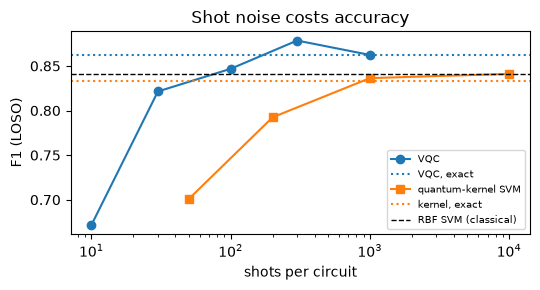

In [20]:
fig, ax = plt.subplots(figsize=(5.5, 3))
xs = [10, 30, 100, 300, 1000, 3000]
ax.semilogx(xs, list(vqc_shots["F1"].iloc[:-1]) + [np.nan], "o-", label="VQC")
ax.axhline(vqc_shots["F1"].iloc[-1], color="tab:blue", ls=":", label="VQC, exact")
ax.semilogx([50, 200, 1000, 10000], qk_shots["F1"].iloc[:-1], "s-", color="tab:orange", label="quantum-kernel SVM")
ax.axhline(qk_shots["F1"].iloc[-1], color="tab:orange", ls=":", label="kernel, exact")
ax.axhline(results["RBF SVM"]["F1"], color="k", ls="--", lw=1, label="RBF SVM (classical)")
ax.set_xlabel("shots per circuit"); ax.set_ylabel("F1 (LOSO)"); ax.set_title("Shot noise costs accuracy")
ax.legend(fontsize=7); plt.tight_layout(); plt.show()

**What just happened?**
- With very few shots, the VQC's prediction for windows near the decision boundary becomes a coin toss, so F1 drops. Somewhere around a few hundred to a thousand shots per window it gets close to the exact result.
- The quantum kernel needs many shots per entry, because SVMs depend on small differences between kernel values. With 50 shots per entry the kernel matrix is very noisy.
- Shots are the hidden cost of quantum models: **every** prediction for **every** window needs hundreds or thousands of circuit runs. A classical model gives its prediction in microseconds.

## 11. Simulated hardware noise

**What it is.** Real qubits make mistakes (notebook 04, section 4). We use a simple, standard noise model:
- **Depolarizing noise**: after each 1-qubit gate, with probability $p$ the qubit gets a random X, Y or Z error; after each CNOT, both qubits do, with probability $10p$ (two-qubit gates are typically about ten times worse; illustrative).
- **Readout error**: when measuring, a true 1 is read as 0 with probability 2% and a true 0 as 1 with probability 1% (illustrative values; reading 1 as 0 is more common on many devices because excited qubits decay).

**How we simulate it.** Random errors turn a single state into a mixture of states, so we switch from a **statevector** to a **density matrix** (a $2^n \times 2^n$ table that can describe mixtures). Trick: a density matrix of n qubits can be stored like a state of 2n qubits; each gate is applied to the first n "ket" axes and its complex conjugate to the last n "bra" axes.

**When the result matters.** We keep the trained weights (trained without noise, as is common) and only add noise when predicting. You could also train with noise in the loop ("noise-aware training"), which costs even more circuit runs.

In [21]:
PAULI_X = np.array([[0, 1], [1, 0]], dtype=CDT)
PAULI_Y = np.array([[0, -1j], [1j, 0]], dtype=CDT)
PAULI_Z = np.array([[1, 0], [0, -1]], dtype=CDT)

def apply_fixed(psi, U, q):
    """Apply one fixed 2x2 matrix U to axis q of every row."""
    a0, a1 = psi[_ix(q, 0)], psi[_ix(q, 1)]; out = np.empty_like(psi)
    out[_ix(q, 0)] = U[0, 0] * a0 + U[0, 1] * a1; out[_ix(q, 1)] = U[1, 0] * a0 + U[1, 1] * a1
    return out

def depolarize(rho, q, n, p):
    """rho -> (1-p) rho + p/3 (X rho X + Y rho Y + Z rho Z) on qubit q (ket axis q, bra axis q+n)."""
    if p == 0: return rho
    out = (1 - p) * rho
    for P_ in (PAULI_X, PAULI_Y, PAULI_Z):
        out = out + (p / 3) * apply_fixed(apply_fixed(rho, P_, q), P_.conj(), q + n)
    return out

def noisy_p_read0(A, params, p1, readout=(0.01, 0.02)):
    """Density-matrix simulation of the trained VQC with depolarizing and readout noise.
    Returns P(qubit 0 is READ as 0) for every window."""
    B, n = A.shape; L = layers_of(params, n); P = L * n * 2; W = params[:P].reshape(L, n, 2)
    rho = zero_states(B, 2 * n)                                   # |0..0><0..0| stored as 2n "qubits"
    for l in range(L):
        for q in range(n):
            for kind, ang in (("y", A[:, q]), ("y", np.full(B, W[l, q, 0])), ("z", np.full(B, W[l, q, 1]))):
                if kind == "y": rho = ry(ry(rho, ang, q), ang, q + n)       # RY is real: same on both sides
                else:           rho = rz(rz(rho, ang, q), -ang, q + n)      # conjugate of RZ(a) is RZ(-a)
                rho = depolarize(rho, q, n, p1)
        for a, b in ring(n):
            rho = cnot(cnot(rho, a, b), a + n, b + n)
            rho = depolarize(depolarize(rho, a, n, min(10 * p1, 0.75)), b, n, min(10 * p1, 0.75))
    diag = np.abs(np.einsum("bii->bi", rho.reshape(B, 2 ** n, 2 ** n)))   # probabilities of each bitstring
    p0_true = diag[:, : 2 ** (n - 1)].sum(1)                              # qubit 0 (left-most bit) is 0
    r01, r10 = readout                                                    # P(read 1 | 0), P(read 0 | 1)
    return p0_true * (1 - r01) + (1 - p0_true) * r10

# Check: with zero noise the density matrix gives the same answer as the statevector
te, A_te, params = fold_store[0]
z_exact = vqc_expval(A_te, params[:16].reshape(1, N_LAYERS, 4, 2))[0]
print("max difference, density matrix (no noise) vs statevector:",
      np.abs(2 * noisy_p_read0(A_te, params, 0.0, (0, 0)) - 1 - z_exact).max())

max difference, density matrix (no noise) vs statevector: 4.7683716e-07


In [22]:
noise_grid = [0.0, 0.001, 0.003, 0.01, 0.03]
rows, squeeze = [], {}
for p1 in noise_grid:
    for shots in [None, 1000]:
        r_ = np.random.default_rng(3); pred = np.zeros_like(y); zs = []
        for te, A_te, params in fold_store:
            ro = (0.0, 0.0) if p1 == 0 else (0.01, 0.02)
            fn = lambda A, prm: noisy_p_read0(A, prm, p1, ro)
            pred[te] = vqc_predict_with_shots(A_te, params, shots, r_, p0_fn=fn)
            if shots is None: zs.append(2 * fn(A_te, params) - 1)
        if shots is None: squeeze[p1] = np.concatenate(zs)
        m = evaluate(y, pred); m.update(p_1q=p1, p_2q=min(10 * p1, 0.75), shots="exact" if shots is None else shots)
        rows.append(m)
noise_df = pd.DataFrame(rows).set_index(["p_1q", "p_2q", "shots"])[["sensitivity", "specificity", "false_alarms", "missed_falls", "F1"]]
print("VQC (4 qubits) under simulated hardware noise (readout error 1%/2% whenever p_1q > 0):")
print(noise_df.round(3))

VQC (4 qubits) under simulated hardware noise (readout error 1%/2% whenever p_1q > 0):
                  sensitivity  specificity  false_alarms  missed_falls     F1
p_1q  p_2q shots                                                             
0.000 0.00 exact        0.979        0.971            14             1  0.862
           1000         0.979        0.971            14             1  0.862
0.001 0.01 exact        0.979        0.971            14             1  0.862
           1000         0.979        0.971            14             1  0.862
0.003 0.03 exact        0.979        0.971            14             1  0.862
           1000         0.979        0.967            16             1  0.847
0.010 0.10 exact        0.979        0.956            21             1  0.810
           1000         0.979        0.946            26             1  0.777
0.030 0.30 exact        0.875        0.125           420             6  0.165
           1000         0.646        0.271           35

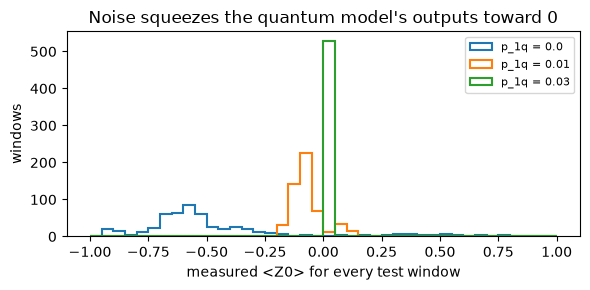

spread (std) of <Z0>: {0.0: 0.365, 0.001: 0.3, 0.003: 0.214, 0.01: 0.062, 0.03: 0.001}


In [23]:
fig, ax = plt.subplots(figsize=(6, 3))
for p1 in [0.0, 0.01, 0.03]:
    ax.hist(squeeze[p1], bins=40, range=(-1, 1), histtype="step", lw=1.5, label=f"p_1q = {p1}")
ax.set_xlabel("measured <Z0> for every test window"); ax.set_ylabel("windows")
ax.set_title("Noise squeezes the quantum model's outputs toward 0"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
print("spread (std) of <Z0>:", {p: round(float(squeeze[p].std()), 3) for p in squeeze})

**What just happened?**
- Noise **squeezes** every output toward 0 (the histogram gets narrower). The model was trained to put its decision threshold at a particular value of $\langle Z_0\rangle$; when all outputs shrink toward 0, normal windows drift across that threshold. In this run the false alarms grow first, and at the highest noise level the outputs are squeezed so close to 0 that the model flags almost every window as a fall. Noise is not just "more randomness"; it **biases** the model.
- Readout errors shift the outputs a little in one direction too.
- At small error rates the damage is small for this shallow 4-qubit circuit. At a few percent per gate it becomes serious, and combining noise with a finite number of shots makes it worse, because a squeezed signal is harder to read through shot noise.
- Deeper circuits, more qubits or more layers would make all of this worse. A classical model on a microcontroller has none of these problems.

## 12. Training and running cost

The measured times below are for **simulation** on this laptop. Below that we estimate what the same work would need on real quantum hardware, counting circuit runs and shots.

In [24]:
time_df = pd.Series(times).rename("total LOSO training time (s), 8 folds").round(3)
print(time_df.to_string())

n_train = int(np.mean([len(tr) for tr, _ in logo.split(X, y, groups)]))
n_test = len(y) // 8
P = N_LAYERS * 4 * 2; steps = 40; shots = 1000
vqc_circuits = steps * (2 * P + 1) * n_train            # parameter-shift training, per fold
kernel_circuits = n_train * (n_train - 1) // 2 + n_test * n_train
print(f"\nPer fold, about {n_train} training windows and {n_test} test windows.")
print(f"VQC training on hardware:    {steps} steps x {2 * P + 1} circuits x {n_train} windows = {vqc_circuits:,} circuits"
      f" -> {vqc_circuits * shots:,} shots at {shots} shots each")
print(f"Quantum kernel on hardware:  {kernel_circuits:,} circuits (train pairs + test-train pairs) -> {kernel_circuits * shots:,} shots")
print(f"VQC prediction for ONE new window: 1 circuit x {shots} shots;  MLP prediction: about 100 multiply-adds")
rate = 1000   # illustrative round number: shots per second, ignoring queues and circuit loading
print(f"\nIf a device ran an illustrative {rate} shots per second: VQC training would take about "
      f"{vqc_circuits * shots / rate / 86400:.0f} days per fold; the kernel about {kernel_circuits * shots / rate / 3600:.0f} hours per fold.")

threshold rule                                        1.098
logistic regression                                   0.058
RBF SVM                                               1.401
MLP (16 hidden)                                       3.870
VQC (4 qubits)                                       20.358
quantum-kernel SVM (4 qubits)                         2.855
angle-encoding kernel (4 qubits, no entanglement)     2.482
amplitude-encoding kernel (2 qubits)                  0.591
quantum-kernel SVM (2 qubits, PCA)                    2.540
VQC (2 qubits, PCA, 2 layers)                         2.253
VQC (2 qubits, PCA, 3 layers)                         4.376
RBF SVM (2 PCA numbers)                               1.496

Per fold, about 462 training windows and 66 test windows.
VQC training on hardware:    40 steps x 33 circuits x 462 windows = 609,840 circuits -> 609,840,000 shots at 1000 shots each
Quantum kernel on hardware:  136,983 circuits (train pairs + test-train pairs) -> 136,983,000 sh

**What just happened?** Even simulated, the VQC is the slowest model to train by far, because every gradient needs 33 circuit evaluations per window (the classical times include their hyperparameter search; logistic regression needs about a tenth of a second for all 8 folds). On real hardware the count of circuit runs and shots becomes the dominant cost: days of device time per fold for a model that a laptop trains in seconds. The shot rate used is an illustrative round number; real devices vary widely and add queue time.

## 13. The full comparison

In [25]:
order = ["always 'no fall'", "threshold rule", "logistic regression", "RBF SVM", "RBF SVM (2 PCA numbers)", "MLP (16 hidden)",
         "VQC (4 qubits)", "VQC (2 qubits, PCA, 3 layers)", "quantum-kernel SVM (4 qubits)", "quantum-kernel SVM (2 qubits, PCA)",
         "angle-encoding kernel (4 qubits, no entanglement)", "amplitude-encoding kernel (2 qubits)"]
final = show(order)
final["train time (s)"] = [round(times.get(n, 0.0), 3) for n in order]
final["kind"] = ["baseline"] + ["classical"] * 5 + ["quantum (simulated, exact)"] * 4 + ["classical in disguise"] * 2
classical = [n for n, k in zip(order, final["kind"]) if k == "classical"]
quantum = [n for n, k in zip(order, final["kind"]) if k.startswith("quantum")]
best_c = max(classical, key=lambda n: results[n]["F1"]); best_q = max(quantum, key=lambda n: results[n]["F1"])
print(f"best classical F1: {results[best_c]['F1']:.3f} ({best_c});  best quantum F1: {results[best_q]['F1']:.3f} ({best_q})")
print("errors (missed falls + false alarms):",
      results[best_c]["missed_falls"] + results[best_c]["false_alarms"], "vs",
      results[best_q]["missed_falls"] + results[best_q]["false_alarms"], "out of", len(y), "windows")
final

best classical F1: 0.870 (MLP (16 hidden));  best quantum F1: 0.882 (quantum-kernel SVM (2 qubits, PCA))
errors (missed falls + false alarms): 14 vs 12 out of 528 windows


,sensitivity,specificity,false_alarms,FA_per_1000,missed_falls,precision,F1,accuracy,train time (s),kind
always 'no fall',0.000,1.000,0,0.000,48,0.000,0.000,0.909,0.000,baseline
threshold rule,0.875,0.985,7,14.583,6,0.857,0.866,0.975,1.098,classical
logistic regression,0.958,0.971,14,29.167,2,0.767,0.852,0.970,0.058,classical
RBF SVM,0.938,0.971,14,29.167,3,0.763,0.841,0.968,1.401,classical
RBF SVM (2 PCA numbers),0.958,0.954,22,45.833,2,0.676,0.793,0.955,1.496,classical
MLP (16 hidden),0.979,0.973,13,27.083,1,0.783,0.870,0.973,3.870,classical
VQC (4 qubits),0.979,0.971,14,29.167,1,0.770,0.862,0.972,20.358,"quantum (simulated, exact)"
"VQC (2 qubits, PCA, 3 layers)",0.938,0.960,19,39.583,3,0.703,0.804,0.958,4.376,"quantum (simulated, exact)"
quantum-kernel SVM (4 qubits),0.917,0.965,17,35.417,4,0.721,0.807,0.960,2.855,"quantum (simulated, exact)"
"quantum-kernel SVM (2 qubits, PCA)",0.938,0.981,9,18.750,3,0.833,0.882,0.977,2.540,"quantum (simulated, exact)"


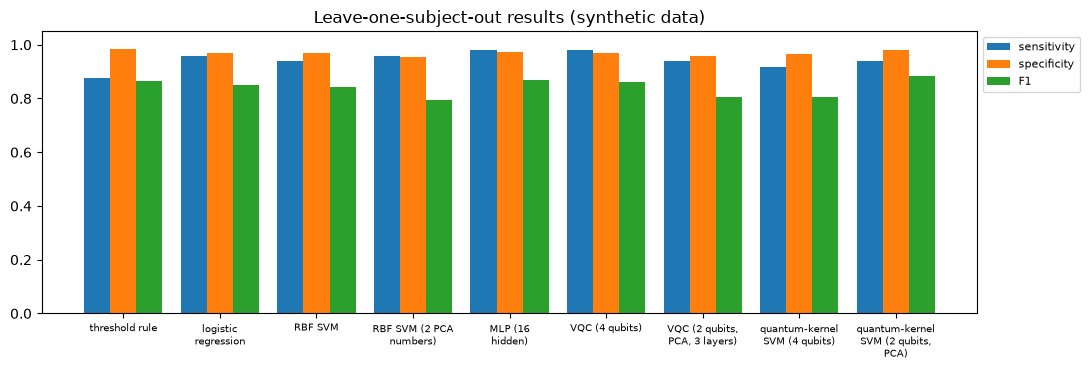

In [26]:
names = order[1:10]
vals = final.loc[names]
import textwrap
fig, ax = plt.subplots(figsize=(11, 3.8))
xpos = np.arange(len(names)); wbar = 0.27
ax.bar(xpos - wbar, vals["sensitivity"], wbar, label="sensitivity")
ax.bar(xpos, vals["specificity"], wbar, label="specificity")
ax.bar(xpos + wbar, vals["F1"], wbar, label="F1")
ax.set_xticks(xpos); ax.set_xticklabels([textwrap.fill(n, 14) for n in names], fontsize=7)
ax.set_ylim(0, 1.05); ax.legend(fontsize=8, loc="upper left", bbox_to_anchor=(1.0, 1.0))
ax.set_title("Leave-one-subject-out results (synthetic data)"); plt.tight_layout(); plt.show()

### Is the difference real? Repeat on new random datasets

One dataset with 48 falls is a small sample. A cheap, honest check: generate **three more** synthetic datasets (new random people, seeds 1, 2, 3), rerun the faster models with exactly the same protocol, and look at the average and spread of F1. (We skip the MLP and the VQCs here only to keep the run time short; the kernel scale grid is reduced to 0.2, 0.35 and 0.5, the values picked most often above.)

In [27]:
saved = dict(y=y, groups=groups, X=X, F_raw=F_raw)            # keep the main dataset safe
rob = {name: [results[name]["F1"]] for name in ["threshold rule", "logistic regression", "RBF SVM",
       "RBF SVM (2 PCA numbers)", "quantum-kernel SVM (4 qubits)", "quantum-kernel SVM (2 qubits, PCA)"]}
t0 = time.perf_counter()
for seed in [1, 2, 3]:
    w_, y_, g_, k_ = make_dataset(rng=np.random.default_rng(seed))
    f_ = extract_features(w_)
    y, groups, X, F_raw = y_, g_, base_features(f_), f_[["peak", "min", "post_var"]].to_numpy()   # swap in the new data
    for name, fp in [("threshold rule", rule_fp), ("logistic regression", logreg_fp), ("RBF SVM", rbf_fp),
                     ("RBF SVM (2 PCA numbers)", rbf_pca2_fp)]:
        pred = np.zeros_like(y)
        for tr, te in logo.split(X, y, groups):
            pred[te] = fp(tr, te)
        rob[name].append(evaluate(y, pred)["F1"])
    rob["quantum-kernel SVM (4 qubits)"].append(evaluate(y, kernel_svm_loso(zz_kernel, [0.2, 0.35, 0.5])[0])["F1"])
    rob["quantum-kernel SVM (2 qubits, PCA)"].append(evaluate(y, kernel_svm_loso(zz_kernel, [0.2, 0.35, 0.5], n_components=2)[0])["F1"])
y, groups, X, F_raw = saved["y"], saved["groups"], saved["X"], saved["F_raw"]   # restore the main dataset
rob_df = pd.DataFrame(rob, index=["seed 42 (main)", "seed 1", "seed 2", "seed 3"]).T
rob_df["mean F1"] = rob_df.mean(axis=1); rob_df["std"] = rob_df.iloc[:, :4].std(axis=1)
print(f"(took {time.perf_counter() - t0:.0f} s)")
rob_df.sort_values("mean F1", ascending=False).round(3)

(took 23 s)


,seed 42 (main),seed 1,seed 2,seed 3,mean F1,std
RBF SVM,0.841,0.949,0.796,0.865,0.863,0.064
quantum-kernel SVM (4 qubits),0.807,0.851,0.807,0.842,0.827,0.023
logistic regression,0.852,0.732,0.803,0.847,0.808,0.056
"quantum-kernel SVM (2 qubits, PCA)",0.882,0.804,0.739,0.786,0.803,0.059
RBF SVM (2 PCA numbers),0.793,0.723,0.734,0.780,0.758,0.034
threshold rule,0.866,0.784,0.682,0.688,0.755,0.088


**How to read this table.**
- All learned models (classical and quantum) catch most falls; the main difference is the number of **false alarms**, which drives precision and F1. The tuned threshold rule trades a few more missed falls for fewer false alarms.
- On the main dataset the best quantum F1 is slightly **above** the best classical one, by about 2 windows out of 528. The repeat on three new datasets shows that this was luck: averaged over 4 datasets, the classical **RBF SVM on 4 features** has the best mean F1, the 4-qubit quantum kernel comes next, and the 2-qubit quantum kernel drops back. The spread from dataset to dataset (std of about 0.02-0.09) is larger than most gaps between models, so **single-run differences of a few points are noise**. This is why research papers must report several runs with error bars (see [experiment design](../24_Research_Methods/02_experiment_design_for_ml.ipynb)).
- With only 48 falls per dataset, one window changes sensitivity by about 2 percentage points.
- So the honest summary is a **tie at best** for the quantum models, and that is with exact simulation, no hardware noise and unlimited shots. With realistic shots and noise (sections 10-11) they get worse, not better, and they cost far more (section 12).

## 14. Conclusion: which wins, and why

**Plainly:** for fall detection from a wearable accelerometer, a **classical** model wins today. On accuracy alone the best quantum models only **tie** with the classical ones (within noise). Once you count everything else, classical wins clearly: a small MLP, an RBF SVM, logistic regression or even a tuned threshold rule on good features trains in a fraction of a second to a few seconds, predicts in microseconds on a cheap chip inside the watch, works offline, and has no shot noise or hardware noise.

**Why the quantum models do not help here.**
1. **The data is classical and small.** Four features and a few hundred windows are an easy problem for classical models. There is no hidden quantum structure to exploit.
2. **Qubits limit the input.** Angle encoding needs one qubit per feature, so the quantum model sees 2-4 hand-made numbers, while a classical model could use the whole raw signal.
3. **Shots and noise** add error to every prediction, and squeeze the model's outputs.
4. **Cost.** Parameter-shift training needs many circuit runs per window per step; on hardware that is days of device time.
5. **Simulability.** A 4-qubit circuit is trivially simulated on a laptop, so it cannot be more powerful than classical computing. Some encodings are even exactly a classical kernel (section 9).
6. **Deployment.** A fall detector must run on the device, in real time, with no network. A cloud quantum computer is the opposite.

**When QML research might matter.**
- **Quantum data**: if the signal itself comes from a quantum system (for example future quantum sensors, such as quantum magnetometers, or outputs of quantum simulations), quantum models can process quantum states directly without the data-loading bottleneck. This "quantum data" setting has the strongest theory.
- **Specially structured problems** where a quantum kernel is proven hard to compute classically (current examples are artificial, built from number-theory problems).
- **Large, error-corrected machines** in the future might change the cost picture; as of late 2026 that is still ahead, and any claim of practical QML advantage on sensor data should be checked against strong classical baselines exactly as we did here.
- **Research and skills**: understanding how to benchmark QML fairly is valuable in its own right.

```mermaid
flowchart TD
    Q[A team asks: should we use<br/>quantum ML for our sensor product?] --> D{Is the data classical?<br/>accelerometer, radar, camera}
    D -->|yes| B[Build strong classical baselines first<br/>features + SVM / MLP / CNN]
    B --> C{Does a QML model beat them under LOSO,<br/>with realistic shots and noise,<br/>at acceptable cost?}
    C -->|almost always no today| U[Ship the classical model.<br/>Keep QML as research]
    C -->|yes, reproducibly| R[Publish it carefully,<br/>then re-check the classical baseline]
    D -->|no, it comes from a quantum system| QQ[Quantum data: the most promising<br/>place for quantum ML research]
```

## 15. What a real project would add (the limits of this notebook)

- **Real data.** Public fall datasets (for example SisFall, MobiAct, UP-Fall) contain real and simulated falls by volunteers; real falls by older adults are rarer and often softer. Synthetic data like ours is useful for teaching and testing pipelines, not for claims.
- **Continuous streams.** A deployed detector slides a window over a continuous signal, so false alarms are counted **per hour or per day** of wear, and the ratio of normal to fall windows is far more extreme than our 10:1.
- **More signals and models.** Gyroscope, orientation, barometer (height change), and deep models on raw windows (1-D CNNs). The classical deep dive is in [26_Sensor_AI/02_imu_activity_recognition_and_fall_detection.ipynb](../26_Sensor_AI/02_imu_activity_recognition_and_fall_detection.ipynb).
- **Uncertainty.** Repeat with several random seeds and report error bars; with few falls, single-run differences are unreliable.

## 16. Optional: the same circuit in PennyLane or Qiskit

If PennyLane or Qiskit is installed, this cell rebuilds the trained VQC of fold 1 with that library and checks that it gives the same $\langle Z_0\rangle$ as our numpy simulator. Otherwise it prints a "skipped" message.

In [28]:
te, A_te, params = fold_store[0]
W1 = params[:16].reshape(N_LAYERS, 4, 2); A5 = A_te[:5]
ours = vqc_expval(A5, W1[None])[0]

try:
    import pennylane as qml
    dev = qml.device("default.qubit", wires=4)

    @qml.qnode(dev)
    def pl_vqc(x, w):
        for l in range(N_LAYERS):
            for q in range(4):
                qml.RY(x[q], wires=q); qml.RY(w[l, q, 0], wires=q); qml.RZ(w[l, q, 1], wires=q)
            for a, b in ring(4):
                qml.CNOT(wires=[a, b])
        return qml.expval(qml.PauliZ(0))

    pl = np.array([float(pl_vqc(x, W1)) for x in A5])
    print("PennyLane <Z0>:", pl.round(4))
    print("numpy     <Z0>:", ours.round(4), "  max difference:", float(np.abs(pl - ours).max()))
except ImportError:
    print("skipped: pip install pennylane")

try:
    from qiskit import QuantumCircuit
    from qiskit.quantum_info import Statevector, SparsePauliOp
    def qk_vqc(x, w):
        qc = QuantumCircuit(4)
        for l in range(N_LAYERS):
            for q in range(4):
                qc.ry(x[q], q); qc.ry(w[l, q, 0], q); qc.rz(w[l, q, 1], q)
            for a, b in ring(4):
                qc.cx(a, b)
        # Qiskit writes qubit 0 as the RIGHT-most letter of a Pauli string
        return Statevector(qc).expectation_value(SparsePauliOp("IIIZ")).real
    qk = np.array([qk_vqc(x, W1) for x in A5])
    print("Qiskit    <Z0>:", qk.round(4), "  max difference:", float(np.abs(qk - ours).max()))
except ImportError:
    print("skipped: pip install qiskit")

PennyLane <Z0>: [-0.685 -0.79  -0.64  -0.64  -0.354]
numpy     <Z0>: [-0.685 -0.79  -0.64  -0.64  -0.354]   max difference: 4.3476730082758763e-07


Qiskit    <Z0>: [-0.685 -0.79  -0.64  -0.64  -0.354]   max difference: 4.347673004945207e-07


## 17. Recap (cheat sheet)

| Topic | Key point |
|---|---|
| Task | fall detection from accelerometer windows: rare positives, hard negatives (jumps, sofa drops), new people |
| Features | peak, min, post-impact variance, jerk; log transforms; standardise; optional PCA |
| Encoding | angle encoding: one qubit per number, angles in [0, π]; amplitude encoding: $\log_2 d$ qubits but costly loading |
| Evaluation | leave-one-subject-out; sensitivity, specificity, false alarms, F1; accuracy is misleading |
| Classical models | threshold rule (weakest), logistic regression, RBF SVM, MLP: fast, strong, deployable |
| VQC | 4 qubits, 2 re-uploading layers, 16 angles + 2 classical numbers; parameter-shift gradients, Adam; comparable, not better |
| Quantum kernel | ZZ feature map + precomputed SVM; scale tuned like an RBF width; comparable, not better |
| Encodings in disguise | angle encoding without entanglement and amplitude encoding are classical kernels |
| Shot noise | error ~ $1/\sqrt{S}$; hundreds to thousands of shots per prediction |
| Hardware noise | depolarizing + readout errors squeeze outputs toward 0 and bias the decisions |
| Cost | simulated training already much slower; on hardware, many millions of shots |
| Verdict | use classical models for sensor data today; QML matters most for quantum data and research |

## 18. Interview questions

1. **Why is accuracy a bad metric for fall detection?** Falls are rare; "never alarm" gets about 91% accuracy here with zero falls caught. Use sensitivity, specificity, false alarms and F1.
2. **Why leave-one-subject-out instead of a random split?** Windows from the same person are similar; a random split leaks that person into training and overstates performance on new users.
3. **How many qubits does angle encoding need for d features?** d, one per feature. Amplitude encoding needs about $\log_2 d$ but a loading circuit of about d gates per sample.
4. **What does shot noise do to a VQC's predictions?** Each $\langle Z\rangle$ is an estimate with error about $1/\sqrt{S}$; windows near the decision boundary flip at random.
5. **What does depolarizing noise do to the outputs?** It shrinks expectation values toward 0, which moves them across a trained threshold and biases predictions.
6. **Why is a kernel from angle encoding without entanglement not "quantum"?** It equals $\prod_i \cos^2((x_i - x_i')/2)$, which a classical computer evaluates directly.
7. **How do you fairly tune a quantum kernel?** Tune its scale (bandwidth) with inner cross-validation on the training subjects only, the same way you tune an RBF SVM's gamma.
8. **When could quantum ML plausibly help?** With quantum data (from quantum sensors or simulations), on problems with proven quantum structure, or on future error-corrected hardware; always against strong classical baselines.

## Further reading

- M. Schuld and F. Petruccione, *Machine Learning with Quantum Computers*, Springer, 2nd ed., 2021.
- V. Havlíček et al., "Supervised learning with quantum-enhanced feature spaces", *Nature* 567 (2019), arXiv:1804.11326.
- M. Schuld and N. Killoran, "Quantum machine learning in feature Hilbert spaces", *Physical Review Letters* (2019).
- A. Pérez-Salinas et al., "Data re-uploading for a universal quantum classifier", *Quantum* (2020).
- K. Mitarai et al., "Quantum circuit learning", *Physical Review A* (2018); M. Schuld et al., "Evaluating analytic gradients on quantum hardware", *Physical Review A* (2019) (parameter-shift rule).
- J. Bowles, S. Ahmed and M. Schuld, "Better than classical? The subtle art of benchmarking quantum machine learning models" (2024).
- S. Thanasilp et al., "Exponential concentration in quantum kernel methods", *Nature Communications* (2024).
- H.-Y. Huang et al., "Power of data in quantum machine learning", *Nature Communications* 12 (2021).
- A. Sucerquia, J. D. López and J. F. Vargas-Bonilla, "SisFall: A Fall and Movement Dataset", *Sensors* 17 (2017).
- PennyLane QML demos (pennylane.ai/qml) and Qiskit Machine Learning documentation.

## Where to go next

- Classical deep dive on this task: [26_Sensor_AI/02_imu_activity_recognition_and_fall_detection.ipynb](../26_Sensor_AI/02_imu_activity_recognition_and_fall_detection.ipynb).
- Back to the theory: [03_quantum_machine_learning.ipynb](03_quantum_machine_learning.ipynb) (encodings, barren plateaus, dequantization) and [04_quantum_ai_tools_hardware_and_industry.ipynb](04_quantum_ai_tools_hardware_and_industry.ipynb) (noise, error correction, AI for quantum).
- Honest benchmarking: [24_Research_Methods/02_experiment_design_for_ml.ipynb](../24_Research_Methods/02_experiment_design_for_ml.ipynb).